In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import platform

In [2]:
sns.set_theme(style='whitegrid')
plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False

In [3]:
tips = pd.read_csv('./data/tips.csv')
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [4]:
tips.shape

(244, 7)

In [5]:
tips.describe() # 숫자 데이터만 볼 수 있음.

,total_bill,tip,size
count,244.000000,244.000000,244.000000
mean,19.785943,2.998279,2.569672
std,8.902412,1.383638,0.951100
min,3.070000,1.000000,1.000000
25%,13.347500,2.000000,2.000000
50%,17.795000,2.900000,2.000000
75%,24.127500,3.562500,3.000000
max,50.810000,10.000000,6.000000


In [6]:
tips['sex'].value_counts()

sex
Male      157
Female     87
Name: count, dtype: int64

In [7]:
tips['smoker'].value_counts()

smoker
No     151
Yes     93
Name: count, dtype: int64

In [8]:
tips['day'].value_counts()

day
Sat     87
Sun     76
Thur    62
Fri     19
Name: count, dtype: int64

In [9]:
tips['time'].value_counts()

time
Dinner    176
Lunch      68
Name: count, dtype: int64

In [10]:
tips['sex'].dtype

<StringDtype(storage='python', na_value=nan)>

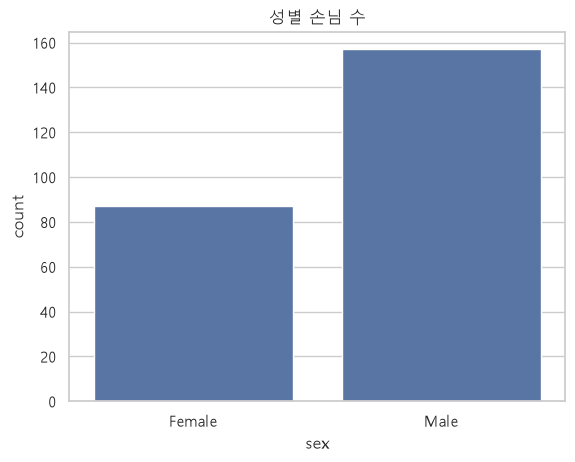

In [11]:
sns.countplot(
    data = tips,
    x = 'sex'
)
plt.title('성별 손님 수')
plt.show()

In [12]:
tips.dtypes

total_bill    float64
tip           float64
sex               str
smoker            str
day               str
time              str
size            int64
dtype: object

In [13]:
tips['day'] = pd.Categorical(tips['day'], categories=['Thur', 'Fri', 'Sat', 'Sun'], ordered=True)
tips['day'].value_counts().sort_index()

day
Thur    62
Fri     19
Sat     87
Sun     76
Name: count, dtype: int64

In [14]:
tips.info()
# 바로 위의 Categorical을 실행한 후면 day의 Dtype이 category로 변경됨.
# 지금은 다시 파일에서 tips를 실행해서 str로 뜨는 거.

<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    str     
 3   smoker      244 non-null    str     
 4   day         244 non-null    category
 5   time        244 non-null    str     
 6   size        244 non-null    int64   
dtypes: category(1), float64(2), int64(1), str(3)
memory usage: 12.0 KB


In [15]:
tips.describe(include='str')

,sex,smoker,time
count,244,244,244
unique,2,2,2
top,Male,No,Dinner
freq,157,151,176


In [16]:
titanic = pd.read_csv('./data/titanic.csv')
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [17]:
titanic.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   survived     891 non-null    int64  
 1   pclass       891 non-null    int64  
 2   sex          891 non-null    str    
 3   age          714 non-null    float64
 4   sibsp        891 non-null    int64  
 5   parch        891 non-null    int64  
 6   fare         891 non-null    float64
 7   embarked     889 non-null    str    
 8   class        891 non-null    str    
 9   who          891 non-null    str    
 10  adult_male   891 non-null    bool   
 11  deck         203 non-null    str    
 12  embark_town  889 non-null    str    
 13  alive        891 non-null    str    
 14  alone        891 non-null    bool   
dtypes: bool(2), float64(2), int64(4), str(7)
memory usage: 92.4 KB


In [18]:
titanic.describe()  # 결측치는 제외하고 계산. age의 mean은 891이 아닌 714로 나눈 것.

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [19]:
titanic.describe(include='str')

,sex,embarked,class,who,deck,embark_town,alive
count,891,889,891,891,203,889,891
unique,2,3,3,3,7,3,2
top,male,S,Third,man,C,Southampton,no
freq,577,644,491,537,59,644,549


In [20]:
titanic.isna().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

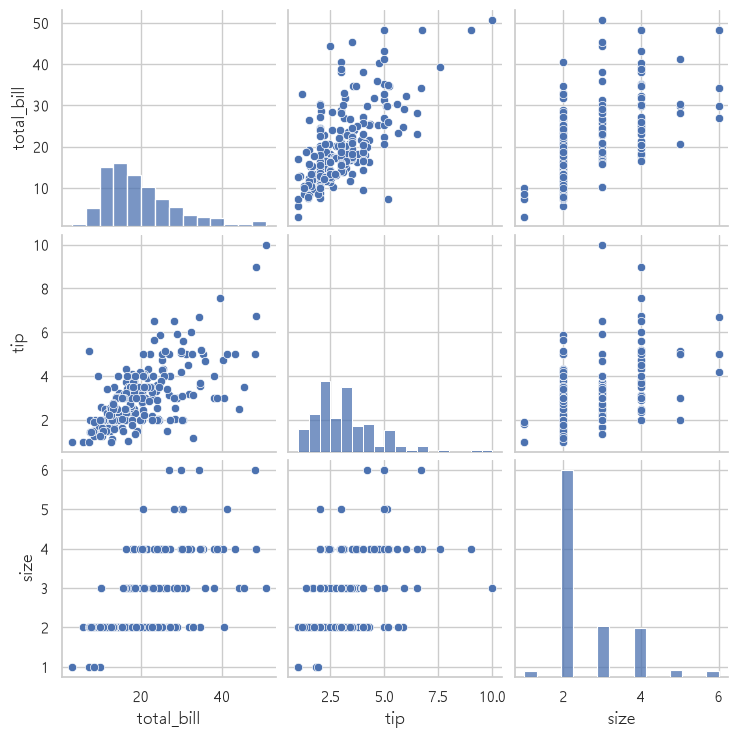

In [21]:
sns.pairplot(
    tips[['total_bill', 'tip', 'size']]
)
plt.show()
# 좌상에서 우하로 가는 대각선(자기 자신)의 경우 해당 데이터(total_bill, tip, size)에서의 변수의 분포를 보여줌.

In [22]:
tips = pd.read_csv('./data/tips.csv')
titanic = pd.read_csv('./data/titanic.csv')

print(tips.head())
print(titanic.head())

   total_bill   tip     sex smoker  day    time  size
0       16.99  1.01  Female     No  Sun  Dinner     2
1       10.34  1.66    Male     No  Sun  Dinner     3
2       21.01  3.50    Male     No  Sun  Dinner     3
3       23.68  3.31    Male     No  Sun  Dinner     2
4       24.59  3.61  Female     No  Sun  Dinner     4
   survived  pclass     sex   age  sibsp  parch     fare embarked  class  \
0         0       3    male  22.0      1      0   7.2500        S  Third   
1         1       1  female  38.0      1      0  71.2833        C  First   
2         1       3  female  26.0      0      0   7.9250        S  Third   
3         1       1  female  35.0      1      0  53.1000        S  First   
4         0       3    male  35.0      0      0   8.0500        S  Third   

     who  adult_male deck  embark_town alive  alone  
0    man        True  NaN  Southampton    no  False  
1  woman       False    C    Cherbourg   yes  False  
2  woman       False  NaN  Southampton   yes   True  
3  

In [23]:
tips['day'] = pd.Categorical(tips['day'], ['Thur', 'Fri', 'Sat', 'Sun'], ordered=True)
titanic['class'] = pd.Categorical(titanic['class'], ['First', 'Second', 'Third'], ordered=True)

In [24]:
tips.info()

<class 'pandas.DataFrame'>
RangeIndex: 244 entries, 0 to 243
Data columns (total 7 columns):
 #   Column      Non-Null Count  Dtype   
---  ------      --------------  -----   
 0   total_bill  244 non-null    float64 
 1   tip         244 non-null    float64 
 2   sex         244 non-null    str     
 3   smoker      244 non-null    str     
 4   day         244 non-null    category
 5   time        244 non-null    str     
 6   size        244 non-null    int64   
dtypes: category(1), float64(2), int64(1), str(3)
memory usage: 12.0 KB


In [25]:
titanic.info()

<class 'pandas.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 15 columns):
 #   Column       Non-Null Count  Dtype   
---  ------       --------------  -----   
 0   survived     891 non-null    int64   
 1   pclass       891 non-null    int64   
 2   sex          891 non-null    str     
 3   age          714 non-null    float64 
 4   sibsp        891 non-null    int64   
 5   parch        891 non-null    int64   
 6   fare         891 non-null    float64 
 7   embarked     889 non-null    str     
 8   class        891 non-null    category
 9   who          891 non-null    str     
 10  adult_male   891 non-null    bool    
 11  deck         203 non-null    str     
 12  embark_town  889 non-null    str     
 13  alive        891 non-null    str     
 14  alone        891 non-null    bool    
dtypes: bool(2), category(1), float64(2), int64(4), str(6)
memory usage: 86.4 KB


In [26]:
titanic['survived_kr'] = titanic['survived'].map({0:'사망', 1:'생존'})
titanic['sex_kr'] = titanic['sex'].map({'male':'남성', 'female':'여성'})
titanic['class_kr'] = titanic['class'].map({'First':'1등석', 'Second':'2등석', 'Third':'3등석'})

titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone,survived_kr,sex_kr,class_kr
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False,사망,남성,3등석
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False,생존,여성,1등석
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True,생존,여성,3등석
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False,생존,여성,1등석
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True,사망,남성,3등석


In [27]:
tips['day'].value_counts().sort_index()

day
Thur    62
Fri     19
Sat     87
Sun     76
Name: count, dtype: int64

In [28]:
freq = tips['day'].value_counts().sort_index()
rel = tips['day'].value_counts(normalize=True).sort_index()
# normalize => 비율

pd.DataFrame({'도수(명)': freq, '비율(%)': (rel * 100).round(1)})

,도수(명),비율(%)
day,,
Thur,62,25.4
Fri,19,7.8
Sat,87,35.7
Sun,76,31.1


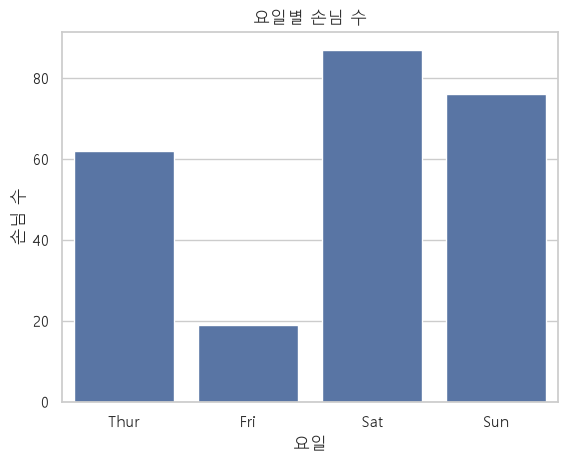

In [29]:
sns.countplot(data=tips, x='day')
plt.title('요일별 손님 수')
plt.xlabel('요일')
plt.ylabel('손님 수')
plt.show()

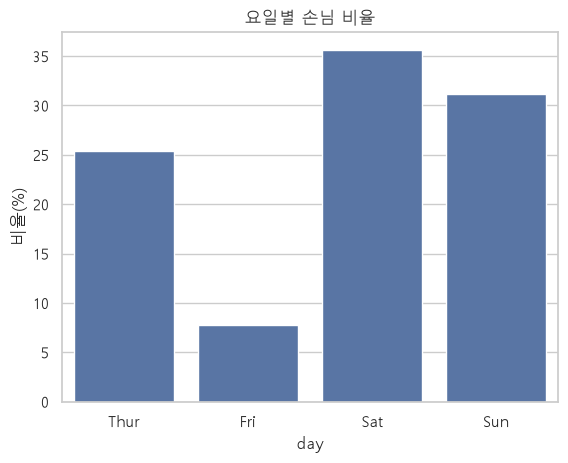

In [30]:
sns.countplot(data=tips, x='day', stat='percent')
plt.title('요일별 손님 비율')
plt.ylabel('비율(%)')
plt.show()

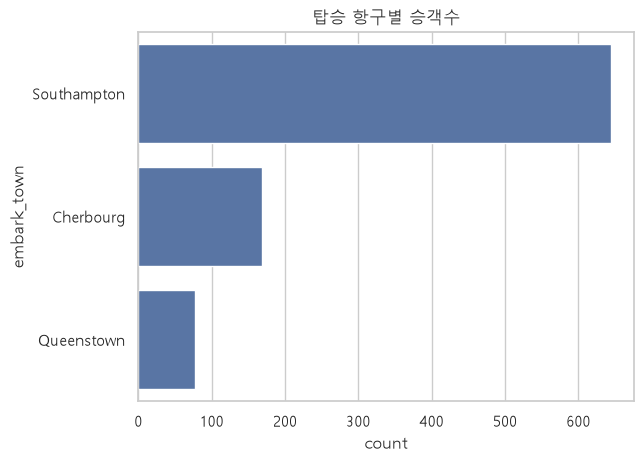

In [31]:
# 옆으로 누운 막대 그래프. y
order = titanic['embark_town'].value_counts().index
sns.countplot(data=titanic, y='embark_town', order=order)
plt.title('탑승 항구별 승객수')
plt.show()

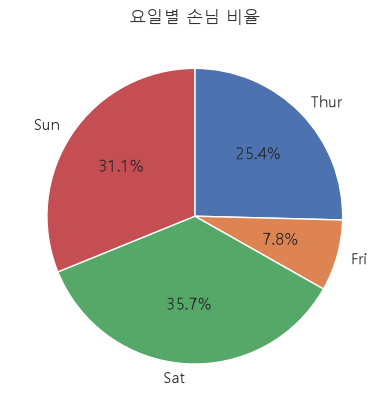

In [32]:
# 원 그래프
counts = tips['day'].value_counts().sort_index()
plt.pie(counts, labels=counts.index, autopct='%.1f%%', startangle=90, counterclock=False)
plt.title('요일별 손님 비율')
plt.show()

In [33]:
ct = pd.crosstab(titanic['sex_kr'], titanic['survived_kr'])
ct

survived_kr,사망,생존
sex_kr,,
남성,468,109
여성,81,233


In [34]:
ct = pd.crosstab(titanic['sex_kr'], titanic['survived_kr'], margins=True, margins_name='합계')
ct

survived_kr,사망,생존,합계
sex_kr,,,
남성,468,109,577
여성,81,233,314
합계,549,342,891


In [35]:
(pd.crosstab(titanic['sex_kr'], titanic['survived_kr'], normalize='index') * 100).round(1)

survived_kr,사망,생존
sex_kr,,
남성,81.1,18.9
여성,25.8,74.2


In [36]:
pd.crosstab([titanic['class'], titanic['sex_kr']], titanic['survived_kr'])

survived_kr     사망  생존
class  sex_kr         
First  남성       77  45
       여성        3  91
Second 남성       91  17
       여성        6  70
Third  남성      300  47
       여성       72  72

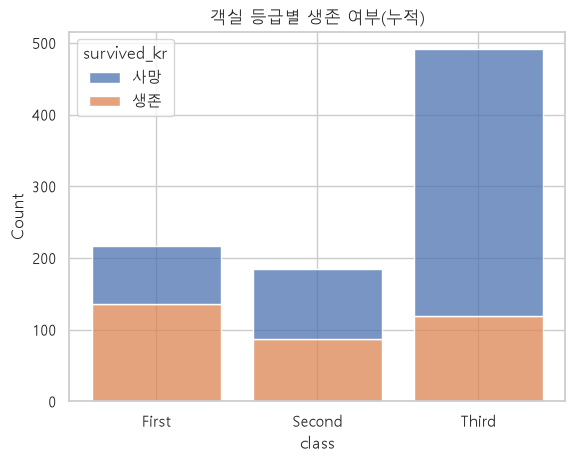

In [37]:
sns.histplot(data=titanic, x='class', hue='survived_kr', multiple='stack', shrink=0.8)
plt.title('객실 등급별 생존 여부(누적)')
plt.show()

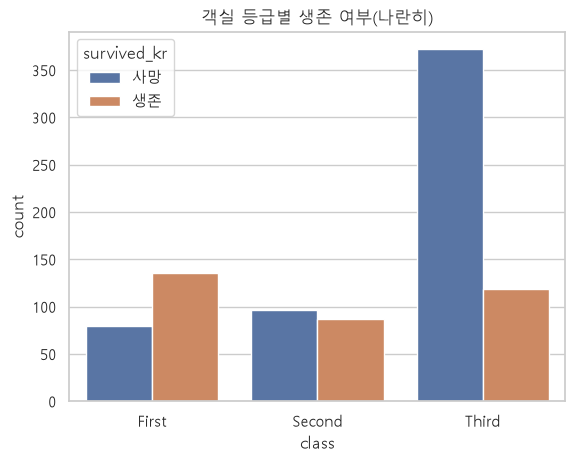

In [38]:
sns.countplot(data=titanic, x='class', hue='survived_kr')
plt.title('객실 등급별 생존 여부(나란히)')
plt.show()

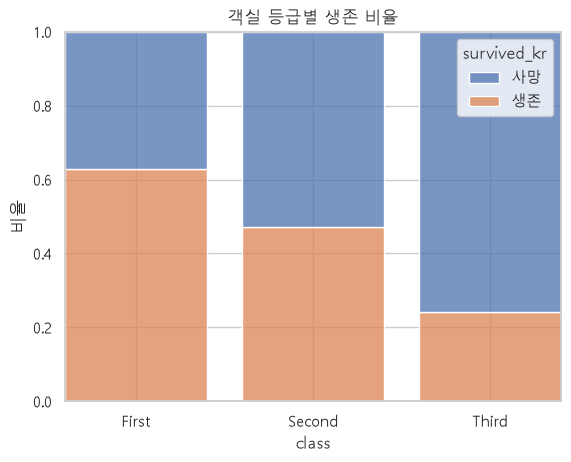

In [39]:
sns.histplot(data=titanic, x='class', hue='survived_kr', multiple='fill', shrink=0.8)
plt.title('객실 등급별 생존 비율')
plt.ylabel('비율')
plt.show()

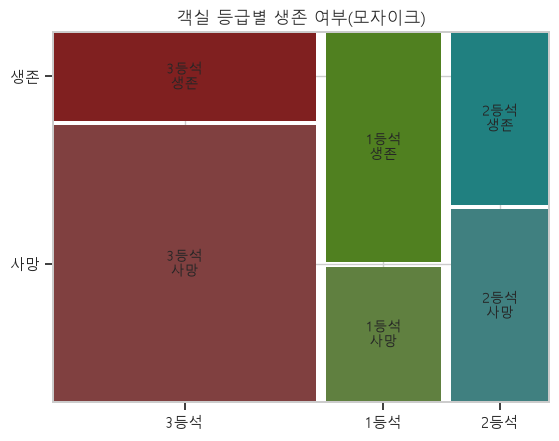

In [40]:
from statsmodels.graphics.mosaicplot import mosaic

mosaic(titanic, ['class_kr', 'survived_kr'], title='객실 등급별 생존 여부(모자이크)', gap=0.02)
plt.show()

In [41]:
# 카이제곱 검정
ct = pd.crosstab(titanic['sex_kr'], titanic['survived_kr'])

print(ct)
print()
print((ct.div(ct.sum(axis=1), axis=0) * 100).round(1))

survived_kr   사망   생존
sex_kr               
남성           468  109
여성            81  233

survived_kr    사망    생존
sex_kr                 
남성           81.1  18.9
여성           25.8  74.2


In [42]:
# 카이제곱 검정
from scipy.stats import chi2_contingency

chi2, p, dof, expected = chi2_contingency(ct)   # chi2_contingency에는 무조건 crosstab이 들어가야 함.

print(f'카이제곱 통계량 = {chi2:.2f}')
print(f'p-값 = {p:.3g}')    # p값이 0.05보다 작으면 관련이 있다고 봄.
print('\n[관계가 없다고 가정했을 때의 기대 도수]')
print(pd.DataFrame(expected, index=ct.index, columns=ct.columns).round(1))

카이제곱 통계량 = 260.72
p-값 = 1.2e-58

[관계가 없다고 가정했을 때의 기대 도수]
survived_kr     사망     생존
sex_kr                   
남성           355.5  221.5
여성           193.5  120.5


In [43]:
## 4장

tips = pd.read_csv('./data/tips.csv')
titanic = pd.read_csv('./data/titanic.csv')
diamonds = pd.read_csv('./data/diamonds.csv')

In [44]:
tips.head()

,total_bill,tip,sex,smoker,day,time,size
0,16.99,1.01,Female,No,Sun,Dinner,2
1,10.34,1.66,Male,No,Sun,Dinner,3
2,21.01,3.50,Male,No,Sun,Dinner,3
3,23.68,3.31,Male,No,Sun,Dinner,2
4,24.59,3.61,Female,No,Sun,Dinner,4


In [45]:
titanic.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [46]:
diamonds.head()

,carat,cut,color,clarity,depth,table,price,x,y,z
0,0.23,Ideal,E,SI2,61.5,55.0,326,3.95,3.98,2.43
1,0.21,Premium,E,SI1,59.8,61.0,326,3.89,3.84,2.31
2,0.23,Good,E,VS1,56.9,65.0,327,4.05,4.07,2.31
3,0.29,Premium,I,VS2,62.4,58.0,334,4.20,4.23,2.63
4,0.31,Good,J,SI2,63.3,58.0,335,4.34,4.35,2.75


In [47]:
bill = tips['total_bill']
bill.head()

0    16.99
1    10.34
2    21.01
3    23.68
4    24.59
Name: total_bill, dtype: float64

In [48]:
bill.mean()     # 평균값

np.float64(19.78594262295082)

In [49]:
bill.median()   # 중위값

np.float64(17.795)

In [50]:
bill.var()      # 분산

np.float64(79.25293861397827)

In [51]:
bill.std()      # 표준편차

np.float64(8.902411954856856)

In [52]:
# 변동계수: 평균대비 퍼져있는 정도.
bill.std() / bill.mean()

# 몸무게.std() / 몸무게.mean()  => kg
# 키.std() / 키.mean()          => cm
# 변동계수가 더 크면 더 들쭉날쭉하다(많이 퍼져있다)는 의미. 서로 다른 단위일 때 비교하기 좋음.

np.float64(0.44993620594706724)

In [53]:
print(bill.quantile([0, 0.25, 0.5, 0.75, 1]))

q1, q3 = bill.quantile(0.25), bill.quantile(0.75)
print('IQR: ', q3 - q1)
print('범위: ', bill.max() - bill.min())
# IQR은 이상치에 강하다(강건하다, 값의 흔들림이 적다). 범위는 이상치에 약함.

0.00     3.0700
0.25    13.3475
0.50    17.7950
0.75    24.1275
1.00    50.8100
Name: total_bill, dtype: float64
IQR:  10.779999999999998
범위:  47.74


In [54]:
# 왜도. 분포가 한쪽으로 기울어진 정도
# 양수: 오른쪽 꼬리가 길다. 음수: 왼쪽 꼬리가 길다.
# 왜도가 0에 가까울 경우, 좌우대칭에 가깝다
bill.skew()

np.float64(1.1332130376158205)

In [55]:
# 첨도. 뾰족한 정도
# 양수: 더 뾰족함. 가운데 어느 특정 데이터값에 많이 몰려있다는 의미.
bill.kurt()

np.float64(1.2184840156638854)

In [56]:
tips[['total_bill', 'tip', 'size']].describe().round(2)

,total_bill,tip,size
count,244.00,244.00,244.00
mean,19.79,3.00,2.57
std,8.90,1.38,0.95
min,3.07,1.00,1.00
25%,13.35,2.00,2.00
50%,17.80,2.90,2.00
75%,24.13,3.56,3.00
max,50.81,10.00,6.00


In [57]:
num = tips[['total_bill', 'tip', 'size']]
summary = num.describe().T  # 딥러닝에서 사용 많음
summary

,count,mean,std,min,25%,50%,75%,max
total_bill,244.0,19.785943,8.902412,3.07,13.3475,17.795,24.1275,50.81
tip,244.0,2.998279,1.383638,1.00,2.0000,2.900,3.5625,10.00
size,244.0,2.569672,0.951100,1.00,2.0000,2.000,3.0000,6.00


In [58]:
bins = [0, 10, 20, 30, 40, 50, 60]
grade = pd.cut(bill, bins=bins, include_lowest=True)
grade.value_counts().sort_index()

total_bill
(-0.001, 10.0]     17
(10.0, 20.0]      130
(20.0, 30.0]       65
(30.0, 40.0]       22
(40.0, 50.0]        9
(50.0, 60.0]        1
Name: count, dtype: int64

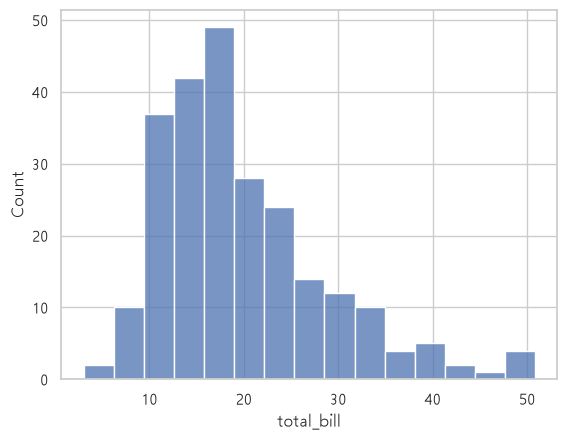

In [59]:
sns.histplot(data=tips, x='total_bill', bins=15)
plt.show()

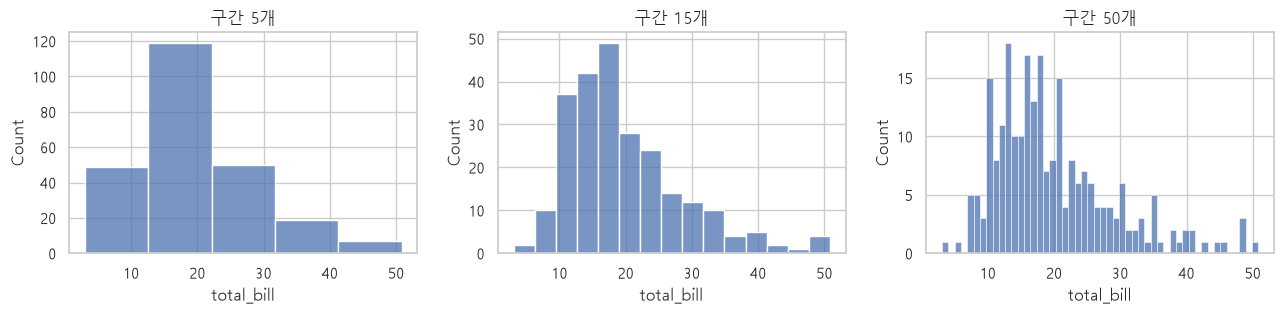

In [60]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.3))
for ax, b in zip(axes, [5, 15, 50]):
    sns.histplot(data=tips, x='total_bill', bins=b, ax=ax)
    ax.set_title(f'구간 {b}개')

plt.tight_layout()
plt.show()

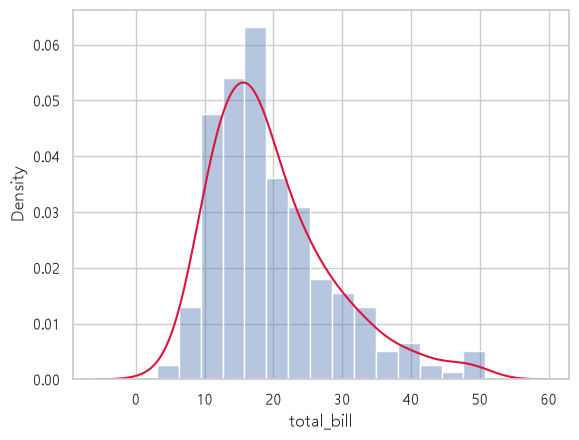

In [61]:
sns.histplot(data=tips, x='total_bill', stat='density', bins=15, alpha=0.4)
sns.kdeplot(data=tips, x='total_bill', color='crimson')
plt.show()

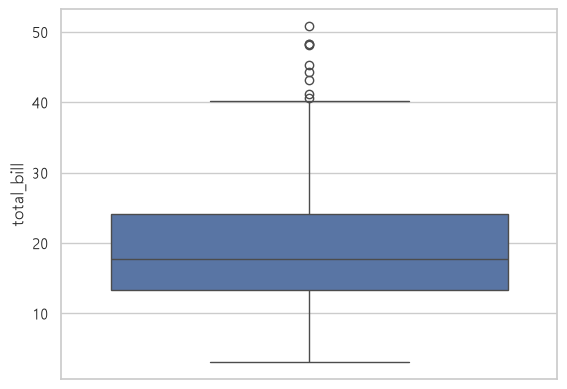

In [62]:
sns.boxplot(data=tips, y='total_bill')
plt.show()

In [63]:
upper = q3 + 1.5 * (q3 - q1)
bill[bill > upper].sort_values()

184    40.55
142    41.19
197    43.11
102    44.30
182    45.35
156    48.17
59     48.27
212    48.33
170    50.81
Name: total_bill, dtype: float64

1.62


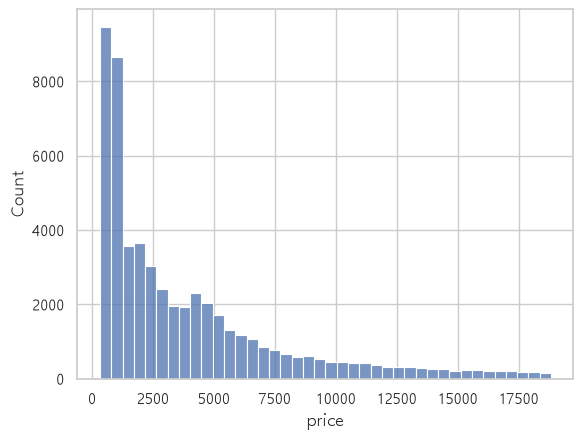

In [64]:
price = diamonds['price']
print(round(price.skew(), 2))

sns.histplot(price, bins=40)
plt.show()

0.12


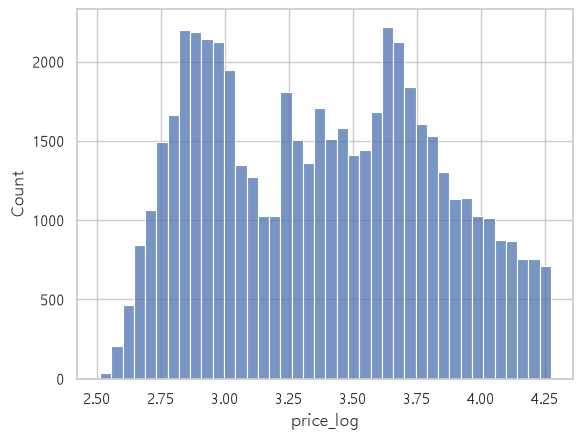

In [65]:
diamonds['price_log'] = np.log10(diamonds['price'])
print(round(diamonds['price_log'].skew(), 2))

sns.histplot(diamonds['price_log'], bins=40)
plt.show()

In [66]:
print(round(tips['total_bill'].corr(tips['tip']), 3))

tips[['total_bill', 'tip', 'size']].corr().round(3)

0.676


,total_bill,tip,size
total_bill,1.000,0.676,0.598
tip,0.676,1.000,0.489
size,0.598,0.489,1.000


In [67]:
titanic[['age', 'fare', 'sibsp', 'parch']].corr().round(3)

,age,fare,sibsp,parch
age,1.000,0.096,-0.308,-0.189
fare,0.096,1.000,0.160,0.216
sibsp,-0.308,0.160,1.000,0.415
parch,-0.189,0.216,0.415,1.000


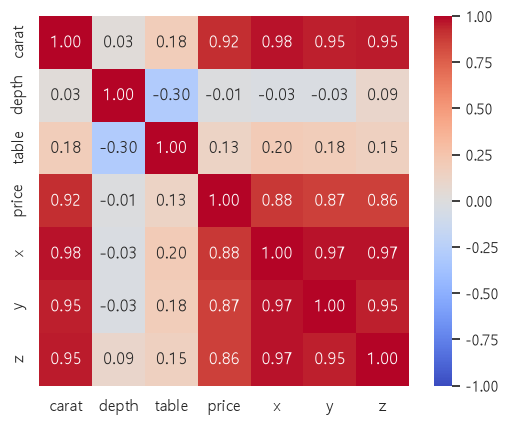

In [68]:
# 상관계수를 일일이 찍기 힘들 때 => 히트맵 그리면 됨.
cols = ['carat', 'depth', 'table', 'price', 'x', 'y', 'z']
corr = diamonds[cols].corr()
sns.heatmap(corr, annot = True, fmt = '.2f', cmap = 'coolwarm', vmin = -1, vmax = 1, square = True)
plt.show()

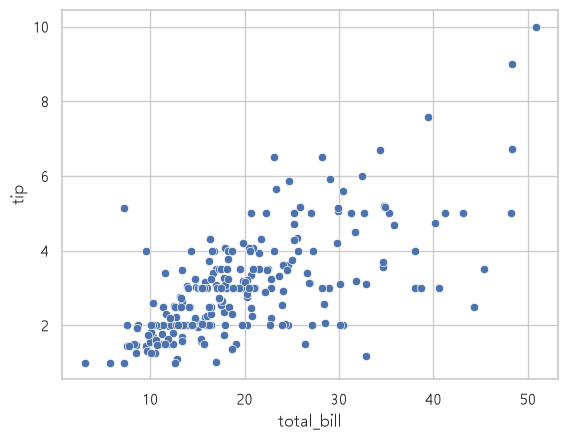

In [69]:
sns.scatterplot(data=tips, x='total_bill', y='tip')
plt.show()

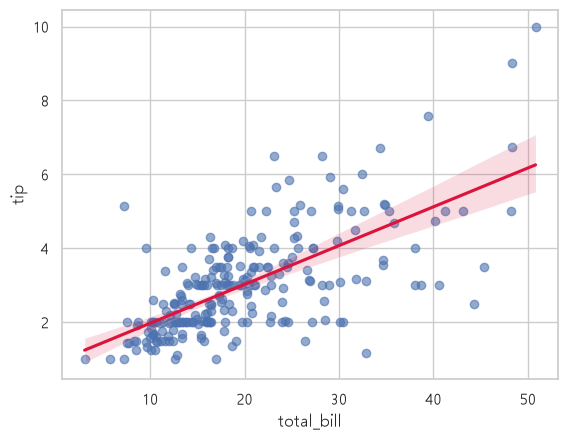

In [70]:
# 직선 추세선. 이 면적 안에서 움직인다는 의미.
sns.regplot(
    data=tips, x='total_bill', y='tip'
    , scatter_kws={'alpha': 0.6}, line_kws={'color':'crimson'}
)
plt.show()

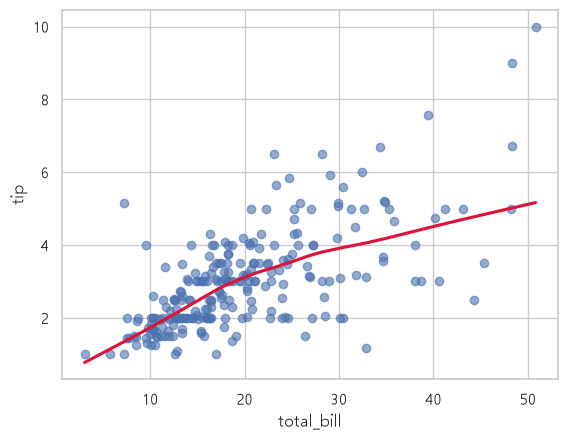

In [71]:
# 곡선 추세선
sns.regplot(
    data=tips, x='total_bill', y='tip', lowess = True
    , scatter_kws={'alpha': 0.6}, line_kws={'color':'crimson'}
)
plt.show()

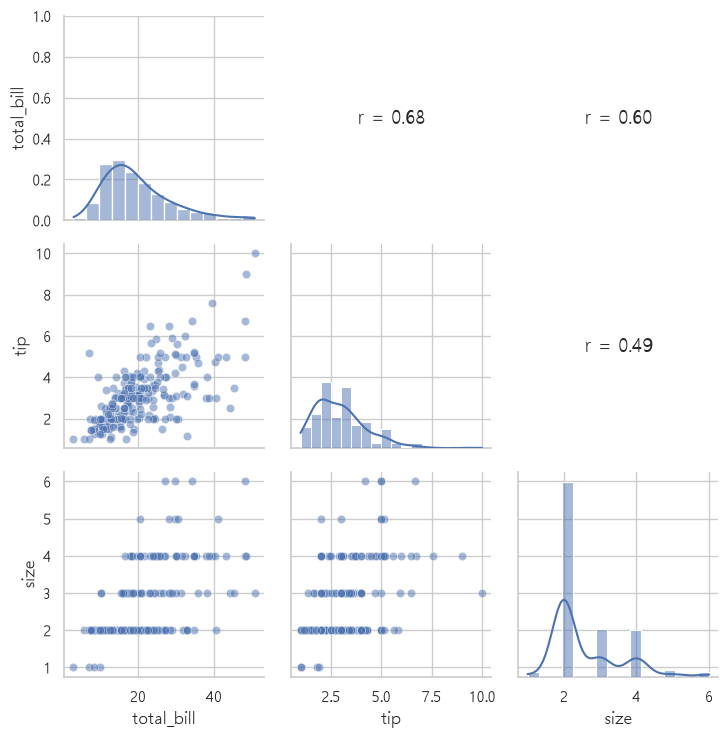

In [72]:
def show_corr(x, y, **kw):                 # 칸 안에 상관계수를 글자로 적어 주는 도우미 함수
    r = x.corr(y)
    ax = plt.gca()
    ax.annotate(f"r = {r:.2f}", (0.5, 0.5), xycoords="axes fraction", ha="center", va="center", fontsize=14)
    ax.set_axis_off()

g = sns.PairGrid(tips[["total_bill", "tip", "size"]])
g.map_diag(sns.histplot, kde=True)       # 대각선: 분포
g.map_lower(sns.scatterplot, alpha=0.5)  # 왼쪽 아래: 산점도
g.map_upper(show_corr)                   # 오른쪽 위: 상관계수
plt.show()

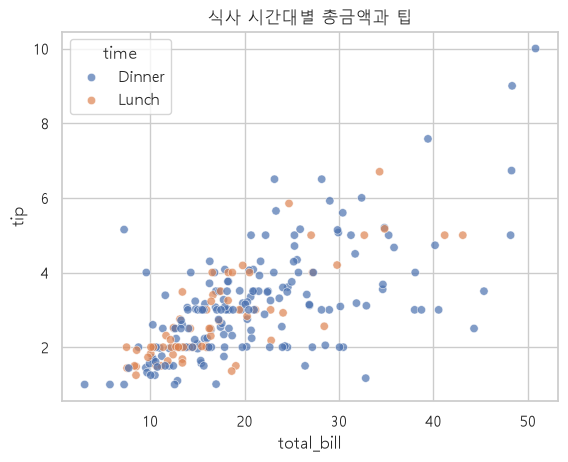

In [73]:
sns.scatterplot(data=tips, x='total_bill', y='tip', hue='time', alpha=0.7)
plt.title('식사 시간대별 총금액과 팁')
plt.show()

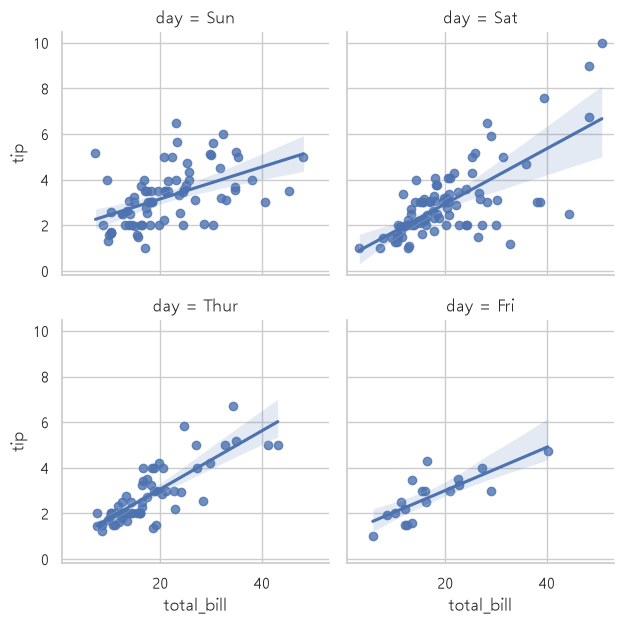

In [74]:
sns.lmplot(data=tips, x='total_bill', y='tip', col='day', col_wrap=2, height=3.2)
plt.show()
# 일, 금, 목, 토 순으로 total_bill과 tip의 상관관계가 크다.

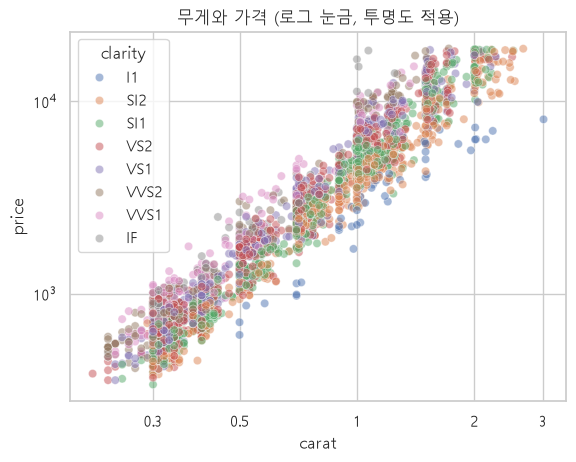

In [75]:
sample = diamonds.sample(3000, random_state=1)   # 5만 개 중 3,000개 무작위 추출
sns.scatterplot(data=sample, x="carat", y="price", hue="clarity", alpha=0.5, hue_order=["I1","SI2","SI1","VS2","VS1","VVS2","VVS1","IF"])
plt.xscale("log"); plt.yscale("log")
plt.xticks([0.3, 0.5, 1, 2, 3], ["0.3", "0.5", "1", "2", "3"])   # 눈금 숫자를 읽기 쉽게
plt.minorticks_off()
plt.title("무게와 가격 (로그 눈금, 투명도 적용)")
plt.show()

In [76]:
# qcut 사용 빈도 낮음.
tips["size_group"] = pd.qcut(tips["total_bill"], 4, labels=["하위25%", "중하", "중상", "상위25%"])   # 금액 기준 4등분
tips["size_group"].value_counts().sort_index()

size_group
하위25%    61
중하       61
중상       61
상위25%    61
Name: count, dtype: int64

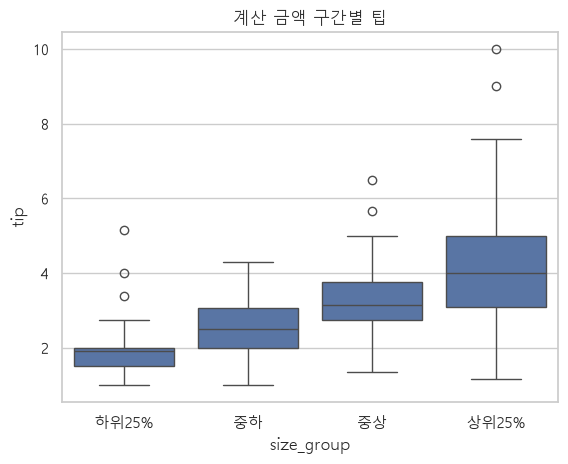

In [77]:
sns.boxplot(data=tips, x="size_group", y="tip")
plt.title("계산 금액 구간별 팁")
plt.show()

In [ ]:
## 5장
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import platform

sns.set_theme(style='whitegrid')             # 그래프 기본 스타일 (이 줄을 먼저!)

# 그래프에서 한글이 깨지지 않게 하는 설정 (운영체제에 맞는 글꼴 선택)
plt.rcParams['font.family'] = {'Darwin': 'Apple SD Gothic Neo', 'Windows': 'Malgun Gothic'}.get(platform.system(), 'NanumGothic')
plt.rcParams['axes.unicode_minus'] = False   # 마이너스(-) 기호 깨짐 방지

In [80]:
tips = pd.read_csv("data/tips.csv")
diamonds = pd.read_csv("data/diamonds.csv")
titanic = pd.read_csv("data/titanic.csv")

tips["day"] = pd.Categorical(tips["day"], ["Thur", "Fri", "Sat", "Sun"], ordered=True)
tips["tip_rate"] = tips["tip"] / tips["total_bill"] * 100    # 팁 비율(%): 금액 대비 팁이 몇 %인지
tips.head()

,total_bill,tip,sex,smoker,day,time,size,tip_rate
0,16.99,1.01,Female,No,Sun,Dinner,2,5.944673
1,10.34,1.66,Male,No,Sun,Dinner,3,16.054159
2,21.01,3.50,Male,No,Sun,Dinner,3,16.658734
3,23.68,3.31,Male,No,Sun,Dinner,2,13.978041
4,24.59,3.61,Female,No,Sun,Dinner,4,14.680765


In [83]:
tips.groupby('sex', observed=True)['total_bill'].mean()

sex
Female    18.056897
Male      20.744076
Name: total_bill, dtype: float64

In [84]:
tips.groupby('sex', observed=True)['total_bill'].agg(['count', 'mean', 'median', 'std', 'min', 'max']).round(2)

,count,mean,median,std,min,max
sex,,,,,,
Female,87,18.06,16.40,8.01,3.07,44.30
Male,157,20.74,18.35,9.25,7.25,50.81


In [ ]:
tips.groupby(['sex', 'smoker'], observed=True)['total_bill'].mean().round(2)

sex     smoker
Female  No        18.11
        Yes       17.98
Male    No        19.79
        Yes       22.28
Name: total_bill, dtype: float64

In [92]:
tips.pivot_table(values='total_bill', index='sex', columns='smoker', aggfunc='mean', observed=True).round(2)

smoker,No,Yes
sex,,
Female,18.11,17.98
Male,19.79,22.28


In [93]:
tips.groupby('day', observed=True).agg(
    손님수 = ('total_bill', 'count'),
    평균금액 = ('total_bill', 'mean'),
    평균팁비율 = ('tip_rate', 'mean')
).round(2)

,손님수,평균금액,평균팁비율
day,,,
Thur,62,17.68,16.13
Fri,19,17.15,16.99
Sat,87,20.44,15.32
Sun,76,21.41,16.69


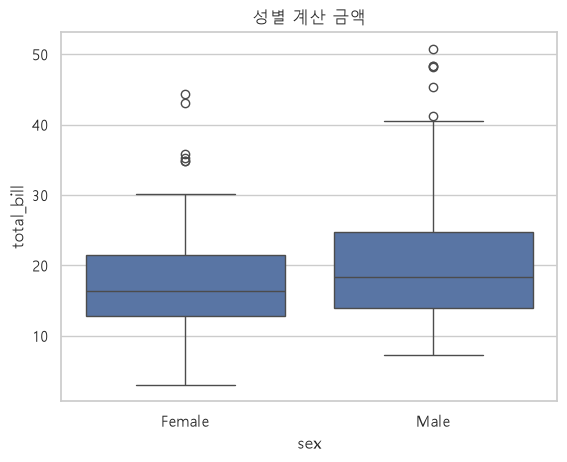

In [94]:
sns.boxplot(data=tips, x="sex", y="total_bill")
plt.title("성별 계산 금액")
plt.show()

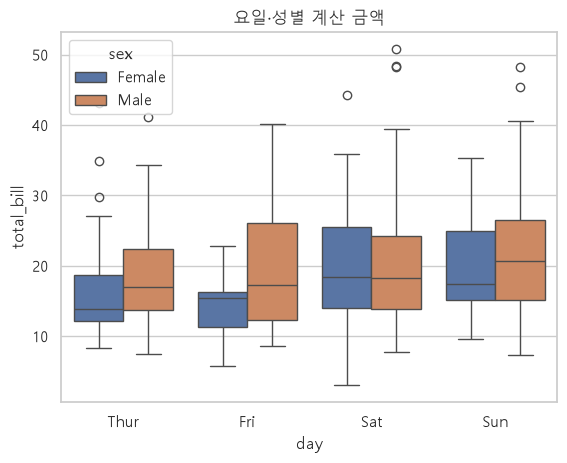

In [96]:
sns.boxplot(data=tips, x="day", y="total_bill", hue="sex")
plt.title("요일·성별 계산 금액")
plt.show()

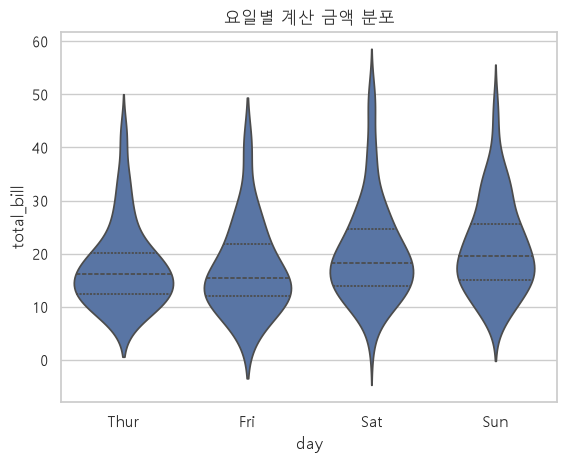

In [97]:
sns.violinplot(data=tips, x="day", y="total_bill", inner="quartile")   # inner: 안쪽에 사분위선 표시
plt.title("요일별 계산 금액 분포")
plt.show()

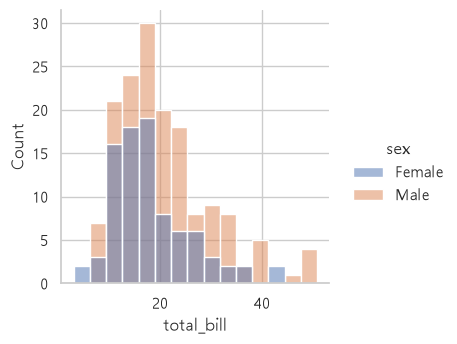

In [101]:
sns.displot(data=tips, x="total_bill", 
            # col="sex", 
            hue='sex',
            bins=15, height=3.6)   # col: 그룹마다 칸 나누기
plt.show()

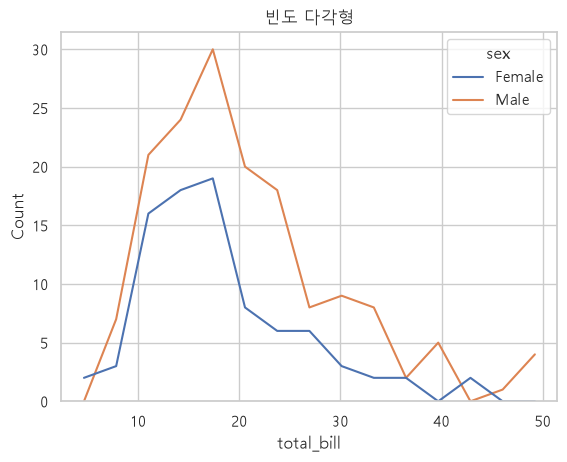

In [102]:
sns.histplot(data=tips, x="total_bill", hue="sex", bins=15, element="poly", fill=False)   # 빈도 다각형
plt.title("빈도 다각형")
plt.show()

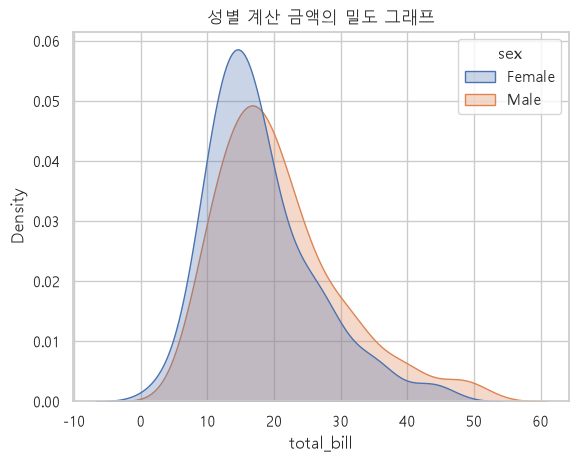

In [103]:
sns.kdeplot(data=tips, x="total_bill", hue="sex", common_norm=False, fill=True, alpha=0.3)
plt.title("성별 계산 금액의 밀도 그래프")
plt.show()

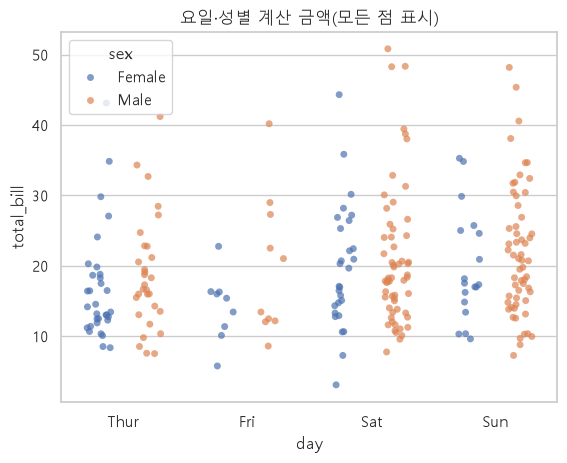

In [104]:
sns.stripplot(data=tips, x="day", y="total_bill", hue="sex", dodge=True, jitter=0.2, alpha=0.7)
plt.title("요일·성별 계산 금액(모든 점 표시)")
plt.show()

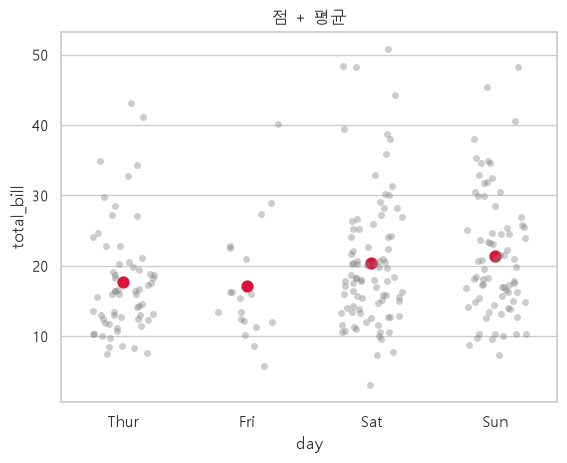

In [105]:
sns.stripplot(data=tips, x="day", y="total_bill", color="gray", alpha=0.4, jitter=0.25)     # 점 + 평균(빨간 점)
sns.pointplot(data=tips, x="day", y="total_bill", color="crimson", linestyle="none", errorbar=None)
plt.title("점 + 평균")
plt.show()

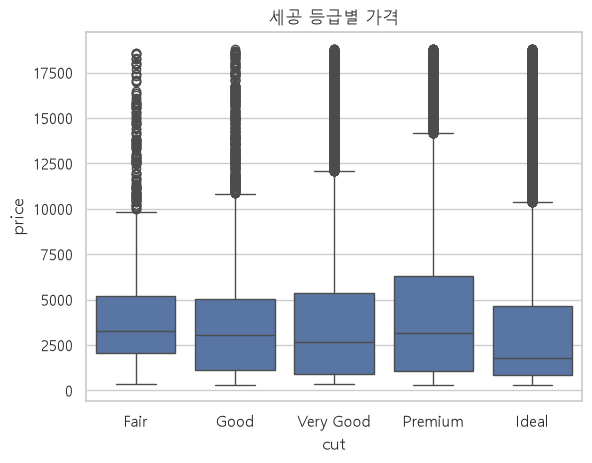

In [106]:
order = ["Fair", "Good", "Very Good", "Premium", "Ideal"]       # 낮은 등급 → 높은 등급
sns.boxplot(data=diamonds, x="cut", y="price", order=order)
plt.title("세공 등급별 가격")
plt.show()

In [107]:
diamonds.groupby('cut')[['price', 'carat']].mean().loc[order].round(2)

,price,carat
cut,,
Fair,4358.76,1.05
Good,3928.86,0.85
Very Good,3981.76,0.81
Premium,4584.26,0.89
Ideal,3457.54,0.70


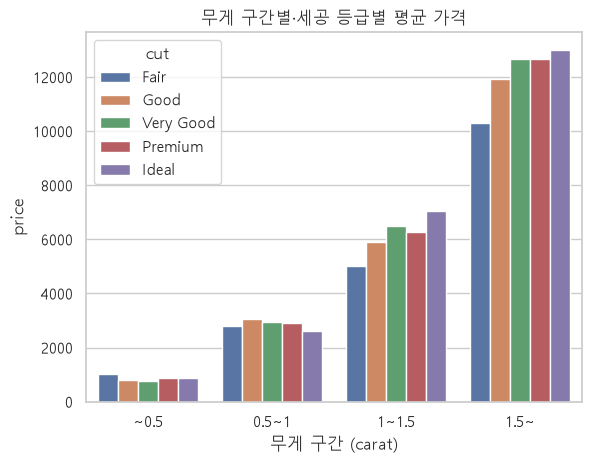

In [108]:
diamonds["carat_group"] = pd.cut(diamonds["carat"], [0, 0.5, 1, 1.5, 5], labels=["~0.5", "0.5~1", "1~1.5", "1.5~"])
sns.barplot(data=diamonds, x="carat_group", y="price", hue="cut", hue_order=order, errorbar=None)
plt.title("무게 구간별·세공 등급별 평균 가격")
plt.xlabel("무게 구간 (carat)")
plt.show()

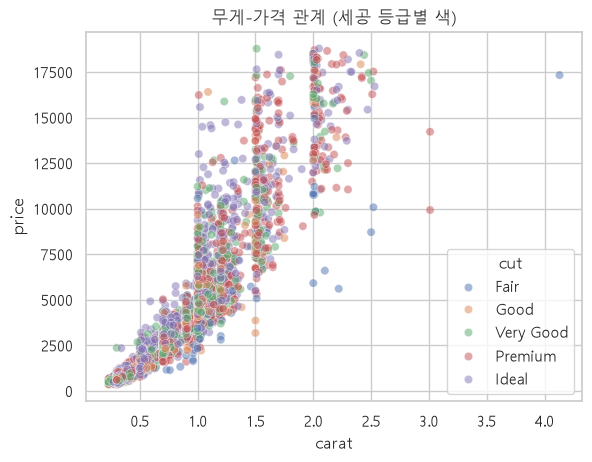

In [111]:
sample = diamonds.sample(4000, random_state=0)
sns.scatterplot(data=sample, x="carat", y="price", hue="cut", hue_order=order, alpha=0.5)
plt.title("무게-가격 관계 (세공 등급별 색)")
plt.show()